# Hyperparameter sweep of the ffNN (xview_recognition)

Auxiliary notebook of the assignment: it shows the results of the experiment sweeps that led to the final ffNN of
`ffNN_example.ipynb`. The runs are executed by `sweep.py` (one function per phase), each one through
`experiment_utils.run_experiment`, and logged to `experiments/experiments.csv` and `experiments/history/<id>.json`.
This notebook only reads those files and draws the figures (saved in `experiments/plots/`).

- **Main metric:** mean recall (macro) on the validation split, because the classes are strongly imbalanced
  (Building 3 594 images vs Helipad 111). Secondary: accuracy, validation loss, per-class recall.
- **Validation split:** 10 % stratified by class (`random_state=1`), seed 1 everywhere. The test set is never used to decide.
- **Reading the capacity plots:** train (dashed) and validation (solid) low and close → underfitting;
  train high and validation clearly lower → overfitting; both high and close → good fit.
- The reasoning and the references behind each decision are in `LOGBOOK.md` (IDs `EXP-###`).

In [1]:
import pandas as pd
from IPython.display import display
import plot_utils as pu

pd.set_option('display.max_colwidth', 60)
COLS = ['id', 'change', 'params', 'actual_epochs', 'best_epoch', 'train_acc', 'val_acc', 'train_mean_recall', 'mean_recall', 'min_recall', 'val_loss', 's_per_epoch']
def table(df):
    display(df[COLS].style.format(precision=3).hide(axis='index'))

I0000 00:00:1791001773.997432   75615 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1791001775.416734   75615 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


## Phase 0: baseline and reproducibility (EXP-001)

The assignment's model (`Flatten → ReLU → Dense(13) → softmax` on raw pixels in [0, 255]), with seed 1 and the new
stratified split. It is the reference for every later phase.

id,change,params,actual_epochs,best_epoch,train_acc,val_acc,train_mean_recall,mean_recall,min_recall,val_loss,s_per_epoch
EXP-001,"baseline (seed 1, stratified split)",1956877,20,12,0.438,0.389,0.345,0.282,0.000,9.829,14.500


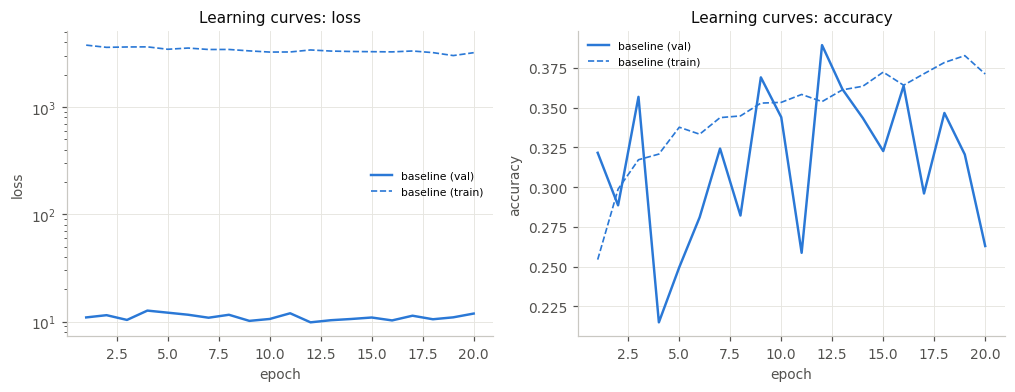

In [2]:
table(pu.load_results(phase=0))
fig, axes = pu.plt.subplots(1, 2, figsize=(11, 3.6))
pu.plot_learning_curves(['EXP-001'], 'loss', labels=['baseline'], ax=axes[0])
pu.plot_learning_curves(['EXP-001'], 'accuracy', labels=['baseline'], ax=axes[1], logy=False)
pu._save(fig, 'phase0_baseline_learning_curves');

**Interpretation.** The loss stays around 10³ for the whole run (a sensible value would be ≈ ln 13 ≈ 2.6) and the
validation accuracy jumps by several points from one epoch to the next: the softmax is saturated because the raw pixels make
the logits huge. Train and validation are both low and close → the model underfits, and the limit is the optimisation.
Two classes (Fishing vessel, Helipad) are never predicted. Baseline: **val acc 0.389, mean recall 0.282**.

## Phase 1: base fixes (EXP-002 → CHG-008 → EXP-003 → EXP-004)

Applied as a cumulative ladder, one change per step, each on top of the previous one:
`Rescaling(1/255)` (EXP-002) → remove the ReLU after `Flatten` and use `keras.Input` (CHG-008, must not change anything)
→ callbacks adapted to the run length: 60 epochs, EarlyStopping patience 10, ReduceLROnPlateau patience 4, comparing the
monitored metric (EXP-003) → per-channel standardisation instead of `/255` (EXP-004). The data cache and batched evaluation
(CHG-007) do not change the model.

id,change,params,actual_epochs,best_epoch,train_acc,val_acc,train_mean_recall,mean_recall,min_recall,val_loss,s_per_epoch
EXP-001,"baseline (seed 1, stratified split)",1956877,20,12,0.438,0.389,0.345,0.282,0.000,9.829,14.500
EXP-002,+ Rescaling(1/255),1956877,20,20,0.550,0.418,0.528,0.365,0.000,4.795,13.510
CHG-008,- ReLU after Flatten (no-op check),1956877,20,20,0.550,0.418,0.528,0.365,0.000,4.795,12.100
EXP-003_val_loss,"callbacks ES10/RLR4, 60 ep, monitor val_loss",1956877,60,50,0.576,0.410,0.564,0.365,0.182,2.688,13.680
EXP-003_val_accuracy,"callbacks ES10/RLR4, 60 ep, monitor val_accuracy",1956877,20,10,0.513,0.417,0.471,0.338,0.081,3.763,12.630
EXP-003_val_mean_recall,"callbacks ES10/RLR4, 60 ep, monitor val_mean_recall",1956877,34,24,0.560,0.413,0.548,0.382,0.199,2.823,12.730
EXP-004,per-channel standardisation (train mean/std),1956877,22,12,0.501,0.367,0.517,0.344,0.181,8.484,12.530


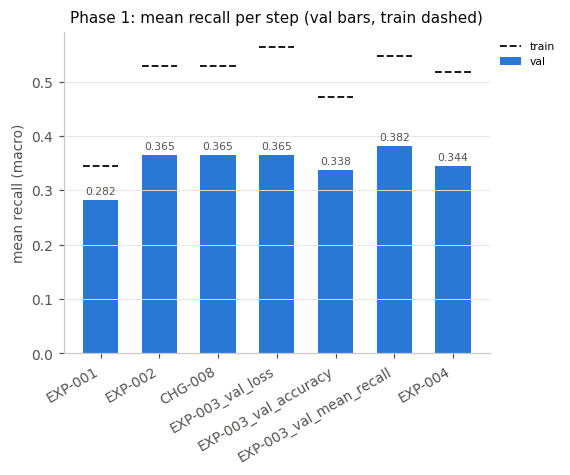

In [3]:
df1 = pu.load_results(phase=1)
table(pd.concat([pu.load_results(phase=0), df1]))
pu.plot_bars(pd.concat([pu.load_results(phase=0), df1]), 'mean_recall', name='phase1_mean_recall_by_step', title='Phase 1: mean recall per step (val bars, train dashed)');

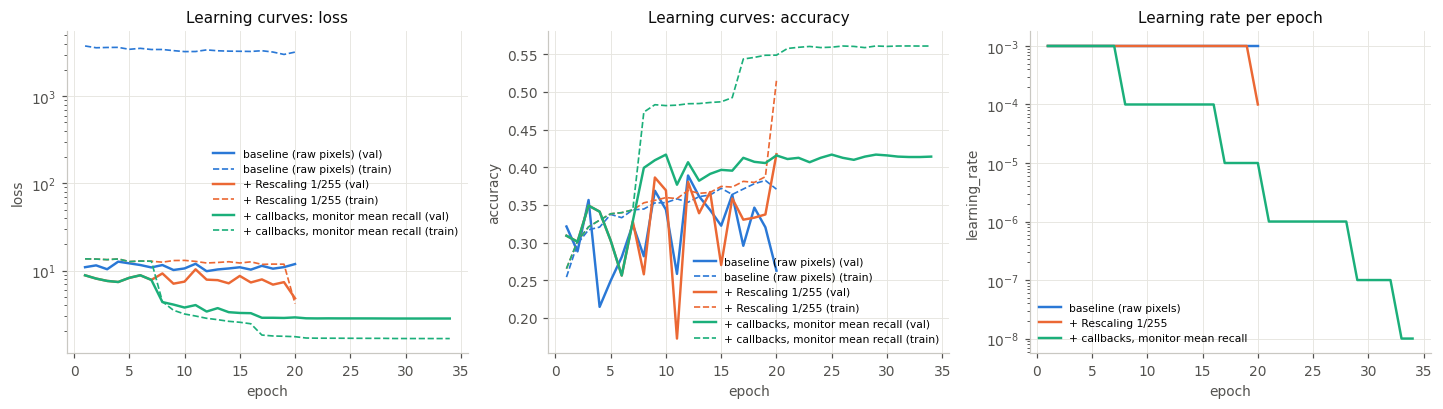

In [4]:
runs = ['EXP-001', 'EXP-002', 'EXP-003_val_mean_recall']
labels = ['baseline (raw pixels)', '+ Rescaling 1/255', '+ callbacks, monitor mean recall']
fig, axes = pu.plt.subplots(1, 3, figsize=(16, 3.8))
pu.plot_learning_curves(runs, 'loss', labels=labels, ax=axes[0])
pu.plot_learning_curves(runs, 'accuracy', labels=labels, ax=axes[1], logy=False)
pu.plot_learning_curves(runs, 'learning_rate', labels=labels, ax=axes[2], title='Learning rate per epoch')
pu._save(fig, 'phase1_learning_curves_baseline_vs_fixed');

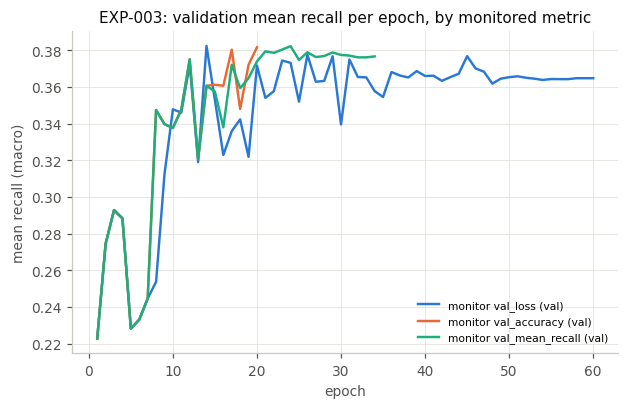

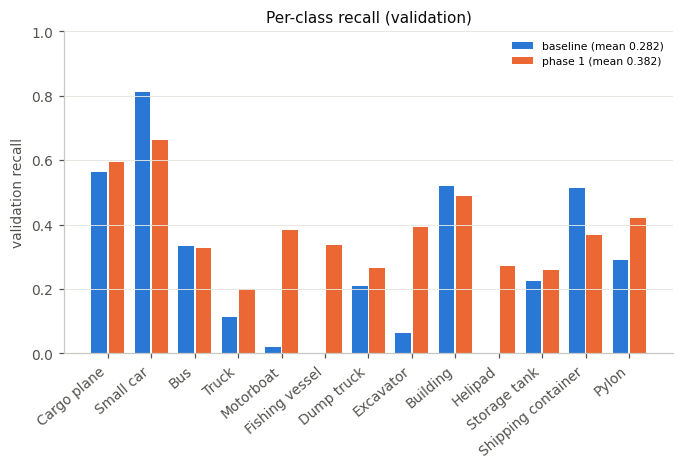

In [5]:
pu.plot_learning_curves(['EXP-003_val_loss', 'EXP-003_val_accuracy', 'EXP-003_val_mean_recall'], 'mean_recall',
                        labels=['monitor val_loss', 'monitor val_accuracy', 'monitor val_mean_recall'], logy=False,
                        name='phase1_monitor_comparison', title='EXP-003: validation mean recall per epoch, by monitored metric');
pu.plot_per_class_recall(['EXP-001', 'EXP-003_val_mean_recall'], labels=['baseline', 'phase 1'], name='phase1_per_class_recall');

**Interpretation.** Scaling the input to [0, 1] is the big change (+8.3 pp of mean recall) and reveals capacity to
fit: train accuracy rises above validation (0.55 vs 0.42). Removing the ReLU after `Flatten` gives exactly the same run,
as expected (ReLU is the identity on non-negative inputs). With callbacks that can actually fire, the learning rate drops
from 1e-3 to ≤ 1e-6, the validation curves stop oscillating, and no class stays at recall 0 any more (min recall ≈ 0.2).
Monitoring `val_accuracy` stops too early on a noisy peak; `val_mean_recall` gives the best mean recall (0.382) and is
also the decision metric, so it is kept. Per-channel standardisation is *worse* (0.344): with Adam at lr 1e-3 a larger
input magnitude makes each step move the logits more, so the softmax saturates harder (epoch-1 loss 60 vs 13.6). This
points to a learning rate that is too high for 150 528 inputs (phase 5).

| Step | Tried | mean recall | Kept for next phase |
|---|---|---|---|
| EXP-002 | `Rescaling(1/255)` | 0.282 → 0.365 | yes |
| CHG-008 | no ReLU after `Flatten`, `keras.Input` | 0.365 (identical) | yes |
| EXP-003 | 60 epochs, ES 10, RLR 4; monitor loss / acc / mean recall | 0.365 / 0.338 / **0.382** | monitor `val_mean_recall` |
| EXP-004 | per-channel standardisation | 0.344 | no, keep `/255` |

**Corrected baseline (end of phase 1): val acc 0.413, mean recall 0.382** (EXP-003_val_mean_recall).